# Credit Card Fraud Detection using Machine Learning



## Objective
Build and evaluate models that identify potentially fraudulent credit-card transactions. The dataset is highly imbalanced, so the project emphasizes **precision, recall, F1-score, PR-AUC, threshold selection, and leakage prevention** rather than accuracy alone.



## 1. Setup and imports

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, precision_recall_curve,
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, accuracy_score, ConfusionMatrixDisplay
)
from sklearn.base import clone
import joblib

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

DATA_PATH = Path("../data/creditcard.csv")
REPORTS_DIR = Path("../reports")
MODELS_DIR = Path("../models")
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Setup complete")

Setup complete


## 2. Load and inspect the data

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. "
        "Download creditcard.csv from the Kaggle link in the README and place it in the data folder."
    )

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
df.info()
display(df.describe().T)

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


## 3. Data quality checks

In [3]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Target values:", df["Class"].value_counts(dropna=False).to_dict())

assert "Class" in df.columns, "Expected target column named 'Class'."
assert set(df["Class"].dropna().unique()).issubset({0, 1}), "Class must be binary (0/1)."

# Remove exact duplicate rows, if any. Keep the first occurrence.
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after duplicate removal:", df.shape)

Missing values: 0


Duplicate rows: 1081
Target values: {0: 284315, 1: 492}


Shape after duplicate removal: (283726, 31)


## 4. Exploratory Data Analysis (EDA)

,count,percentage
Class,,
Legitimate (0),283253,99.8333
Fraud (1),473,0.1667


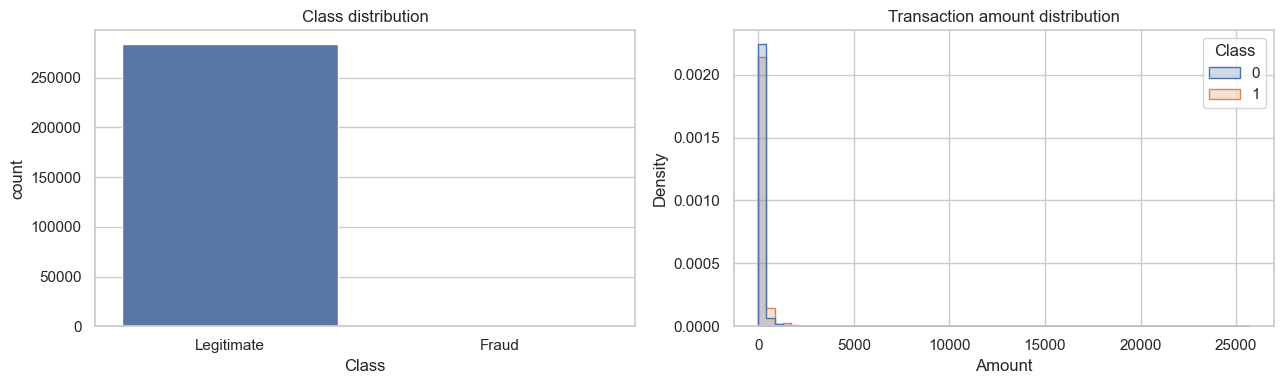

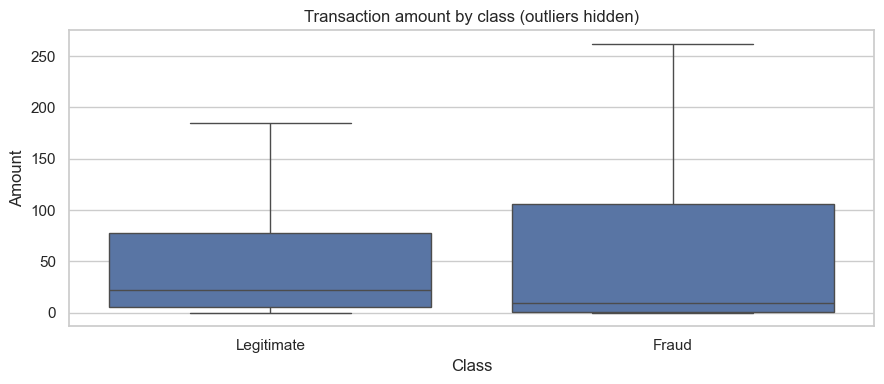

In [4]:
class_counts = df["Class"].value_counts().sort_index()
display(pd.DataFrame({
    "count": class_counts,
    "percentage": (class_counts / len(df) * 100).round(4)
}).rename(index={0: "Legitimate (0)", 1: "Fraud (1)"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x="Class", ax=axes[0])
axes[0].set_title("Class distribution")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Legitimate", "Fraud"])
sns.histplot(data=df, x="Amount", hue="Class", bins=60, stat="density",
             common_norm=False, element="step", ax=axes[1])
axes[1].set_title("Transaction amount distribution")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=df, x="Class", y="Amount", showfliers=False, ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Legitimate", "Fraud"])
ax.set_title("Transaction amount by class (outliers hidden)")
plt.tight_layout()
plt.show()

## 5. Prepare features and split data without leakage

In [5]:
X = df.drop(columns=["Class"])
y = df["Class"].astype(int)

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, test_size=0.25,
    random_state=RANDOM_STATE, stratify=y_train_full
)

print("Train:", X_train.shape, "Fraud rate:", y_train.mean())
print("Validation:", X_valid.shape, "Fraud rate:", y_valid.mean())
print("Test:", X_test.shape, "Fraud rate:", y_test.mean())

numeric_to_scale = ["Time", "Amount"]
preprocessor = ColumnTransformer(
    transformers=[("scale", StandardScaler(), numeric_to_scale)],
    remainder="passthrough"
)

Train: (170235, 30) Fraud rate: 0.0016682820806532147
Validation: (56745, 30) Fraud rate: 0.0016565336152965019
Test: (56746, 30) Fraud rate: 0.0016741268107003137


## 6. Train baseline and ensemble models

In [6]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", LogisticRegression(
            max_iter=2000, class_weight="balanced", solver="lbfgs",
            random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", RandomForestClassifier(
            n_estimators=250, max_depth=None, min_samples_leaf=2,
            class_weight="balanced_subsample", n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ]),
    "HistGradientBoosting": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", HistGradientBoostingClassifier(
            max_iter=150, learning_rate=0.08, max_leaf_nodes=15,
            l2_regularization=1.0, class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])
}

fitted_models = {}
validation_rows = []

for name, pipe in models.items():
    print(f"Training {name} ...")
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    valid_scores = pipe.predict_proba(X_valid)[:, 1]
    validation_rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_valid, valid_scores),
        "PR-AUC (Average Precision)": average_precision_score(y_valid, valid_scores),
        "Precision @ 0.5": precision_score(y_valid, valid_scores >= 0.5, zero_division=0),
        "Recall @ 0.5": recall_score(y_valid, valid_scores >= 0.5, zero_division=0),
        "F1 @ 0.5": f1_score(y_valid, valid_scores >= 0.5, zero_division=0)
    })

validation_results = pd.DataFrame(validation_rows).sort_values(
    "PR-AUC (Average Precision)", ascending=False
)
display(validation_results)
validation_results.to_csv(REPORTS_DIR / "validation_model_comparison.csv", index=False)

Training Logistic Regression ...


Training Random Forest ...


Training HistGradientBoosting ...


,Model,ROC-AUC,PR-AUC (Average Precision),Precision @ 0.5,Recall @ 0.5,F1 @ 0.5
1,Random Forest,0.954332,0.869506,0.918605,0.840426,0.877778
0,Logistic Regression,0.978839,0.786826,0.053832,0.904255,0.101614
2,HistGradientBoosting,0.969945,0.778157,0.214834,0.893617,0.346392


## 7. Compare validation precision-recall curves

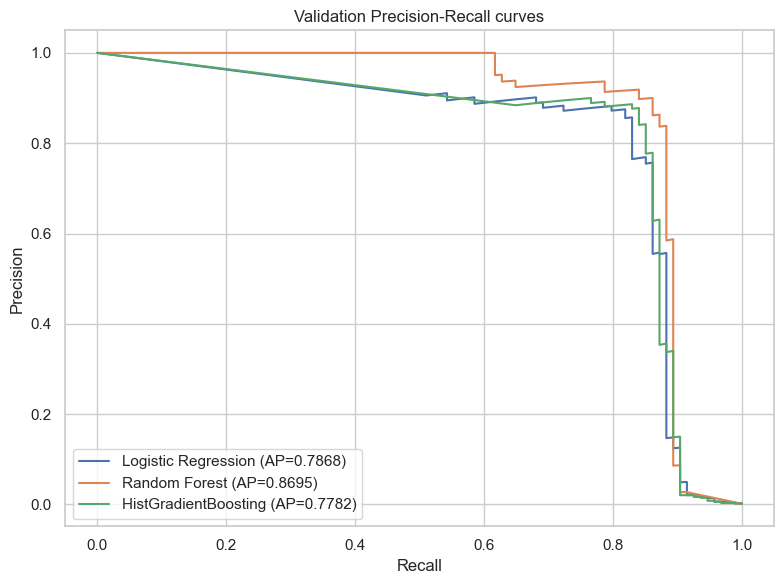

In [7]:
plt.figure(figsize=(8, 6))
for name, pipe in fitted_models.items():
    scores = pipe.predict_proba(X_valid)[:, 1]
    precision, recall, _ = precision_recall_curve(y_valid, scores)
    ap = average_precision_score(y_valid, scores)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.4f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation Precision-Recall curves")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Select a decision threshold using validation data

Selected model: Random Forest
Validation-selected threshold: 0.343771
Validation precision: 0.9
Validation recall: 0.8617
Validation F1: 0.8804


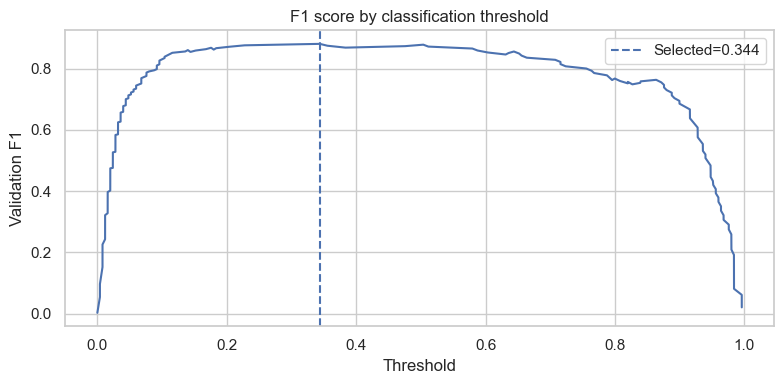

In [8]:
best_name = validation_results.iloc[0]["Model"]
best_model = fitted_models[best_name]
valid_scores = best_model.predict_proba(X_valid)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_valid, valid_scores)
# precision_recall_curve returns one more precision/recall point than thresholds.
f1_values = (2 * precisions[:-1] * recalls[:-1]) / (
    precisions[:-1] + recalls[:-1] + 1e-12
)
best_idx = int(np.nanargmax(f1_values))
best_threshold = float(thresholds[best_idx])

print("Selected model:", best_name)
print("Validation-selected threshold:", round(best_threshold, 6))
print("Validation precision:", round(float(precisions[best_idx]), 4))
print("Validation recall:", round(float(recalls[best_idx]), 4))
print("Validation F1:", round(float(f1_values[best_idx]), 4))

plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_values)
plt.axvline(best_threshold, linestyle="--", label=f"Selected={best_threshold:.3f}")
plt.xlabel("Threshold")
plt.ylabel("Validation F1")
plt.title("F1 score by classification threshold")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Final evaluation on the untouched test set

,Test result
Selected model,Random Forest
Threshold,0.343771
Accuracy,0.999471
Precision,0.933333
Recall,0.736842
F1-score,0.823529
ROC-AUC,0.938077
PR-AUC (Average Precision),0.814671


              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.93      0.74      0.82        95

    accuracy                           1.00     56746
   macro avg       0.97      0.87      0.91     56746
weighted avg       1.00      1.00      1.00     56746



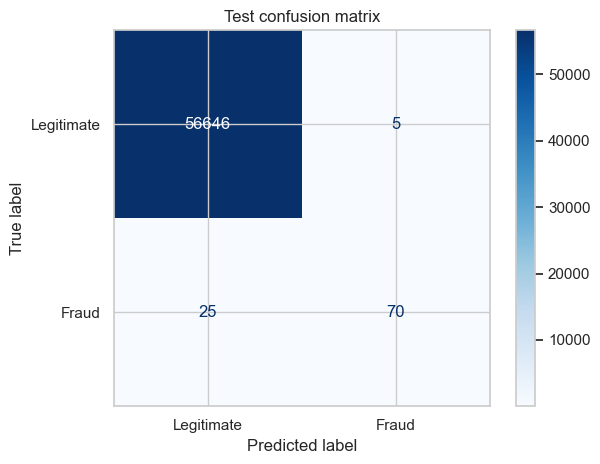

In [9]:
test_scores = best_model.predict_proba(X_test)[:, 1]
test_predictions = (test_scores >= best_threshold).astype(int)

test_metrics = {
    "Selected model": best_name,
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1-score": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_scores),
    "PR-AUC (Average Precision)": average_precision_score(y_test, test_scores)
}
display(pd.DataFrame([test_metrics]).T.rename(columns={0: "Test result"}))
print(classification_report(y_test, test_predictions, target_names=["Legitimate", "Fraud"], zero_division=0))

cm = confusion_matrix(y_test, test_predictions)
ConfusionMatrixDisplay(cm, display_labels=["Legitimate", "Fraud"]).plot(
    values_format="d", cmap="Blues"
)
plt.title("Test confusion matrix")
plt.tight_layout()
plt.show()

pd.DataFrame([test_metrics]).to_csv(REPORTS_DIR / "final_test_metrics.csv", index=False)

## 10. Optional experiment: SMOTE on training data only

In [10]:
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE

    smote_model = ImbPipeline([
        ("preprocess", clone(preprocessor)),
        ("smote", SMOTE(random_state=RANDOM_STATE, sampling_strategy=0.15)),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ])
    smote_model.fit(X_train, y_train)
    smote_valid_scores = smote_model.predict_proba(X_valid)[:, 1]
    print("SMOTE Logistic Regression validation PR-AUC:",
          round(average_precision_score(y_valid, smote_valid_scores), 5))
    print("Compare this with the class-weighted Logistic Regression above.")
except ImportError:
    print("imbalanced-learn is not installed. Run: pip install imbalanced-learn")

imbalanced-learn is not installed. Run: pip install imbalanced-learn


## 11. Model interpretation

,Feature,Importance
15,V14,0.189419
5,V4,0.117359
13,V12,0.114907
11,V10,0.096449
18,V17,0.085840
12,V11,0.075324
4,V3,0.056302
17,V16,0.035346
8,V7,0.026056
3,V2,0.020797


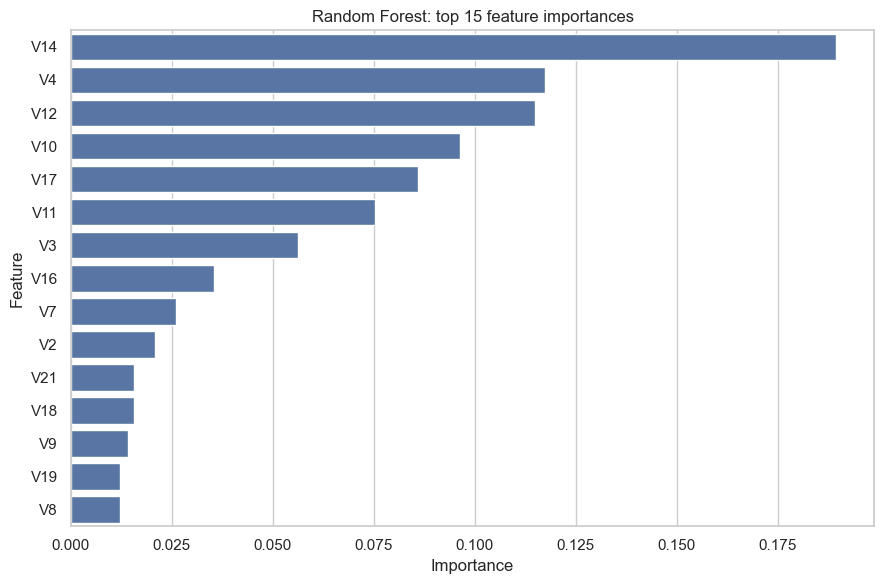

In [11]:
rf_pipe = fitted_models.get("Random Forest")
if rf_pipe is not None:
    importances = rf_pipe.named_steps["model"].feature_importances_
    # ColumnTransformer outputs the scaled columns first, then the passthrough columns.
    feature_names = numeric_to_scale + [c for c in X_train.columns if c not in numeric_to_scale]
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False).head(15)

    display(importance_df)
    plt.figure(figsize=(9, 6))
    sns.barplot(data=importance_df, x="Importance", y="Feature")
    plt.title("Random Forest: top 15 feature importances")
    plt.tight_layout()
    plt.show()

## 12. Save the selected model and project outputs

In [12]:
model_path = MODELS_DIR / "fraud_detection_model.joblib"
joblib.dump({
    "model": best_model,
    "threshold": best_threshold,
    "model_name": best_name,
    "feature_columns": list(X.columns)
}, model_path)

print("Saved model to:", model_path.resolve())
print("Saved reports to:", REPORTS_DIR.resolve())

Saved model to: C:\Users\shaya\credit_card_fraud_detection\models\fraud_detection_model.joblib
Saved reports to: C:\Users\shaya\credit_card_fraud_detection\reports
